# 03 — Autocorrelación espacial (Moran y LISA)

Siguiendo la tradición de Anselin (1995), cuantificamos la **dependencia espacial** del voto y de la marginación: el Índice de Moran global mide el grado de agrupamiento espacial, y los indicadores locales (LISA) identifican *clusters* significativos (Alto-Alto, Bajo-Bajo) y valores atípicos espaciales.

In [1]:
import sys, os
sys.path.insert(0, os.path.join("..", "src"))
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

BASE = os.path.join("..")
PROCESADOS = os.path.join(BASE, "data", "processed")
FIGURAS = os.path.join(BASE, "figuras")
os.makedirs(FIGURAS, exist_ok=True)

df = pd.read_csv(os.path.join(PROCESADOS, "municipios_electoral_social.csv"),
                 dtype={"cvegeo": str})
gdf = gpd.read_file(os.path.join(PROCESADOS, "municipios_cartografia_simplificada.gpkg"))
gdf["cvegeo"] = gdf["cvegeo"].str.zfill(5)
gdf = gdf.merge(df, on="cvegeo", how="left")
print(f"{len(df)} municipios con datos, {len(gdf)} polígonos")
gdf.head(3)
from libpysal.weights import Queen
from esda.moran import Moran, Moran_Local
from splot.esda import plot_moran, lisa_cluster


2469 municipios con datos, 2478 polígonos


In [2]:
g = gdf.dropna(subset=["pct_sheinbaum", "im_2020"]).reset_index(drop=True)
w = Queen.from_dataframe(g, use_index=False)
w.transform = "r"
print(f"Municipios: {len(g)} | vecinos promedio: {w.mean_neighbors:.1f}")

for col, nombre in [("pct_sheinbaum", "% Sheinbaum"), ("im_2020", "Marginación"),
                    ("pct_participacion", "Participación")]:
    mi = Moran(g[col], w, permutations=999)
    print(f"{nombre}: I = {mi.I:.3f}, p-valor = {mi.p_sim:.4f} -> "
          f"{'autocorrelación significativa' if mi.p_sim < 0.05 else 'no significativa'}")

/home/appuser/.local/lib/python3.12/site-packages/libpysal/weights/contiguity.py:354: UserWarning: The weights matrix is not fully connected: 
 There are 7 disconnected components.
 There are 5 islands with ids: 1210, 1276, 1277, 2027, 2030.
  W.__init__(self, neighbors, ids=ids, **kw)


('WARNING: ', 1210, ' is an island (no neighbors)')
('WARNING: ', 1276, ' is an island (no neighbors)')
('WARNING: ', 1277, ' is an island (no neighbors)')
('WARNING: ', 2027, ' is an island (no neighbors)')
('WARNING: ', 2030, ' is an island (no neighbors)')
Municipios: 2462 | vecinos promedio: 4.8
% Sheinbaum: I = 0.544, p-valor = 0.0010 -> autocorrelación significativa
Marginación: I = 0.646, p-valor = 0.0010 -> autocorrelación significativa


Participación: I = 0.387, p-valor = 0.0010 -> autocorrelación significativa


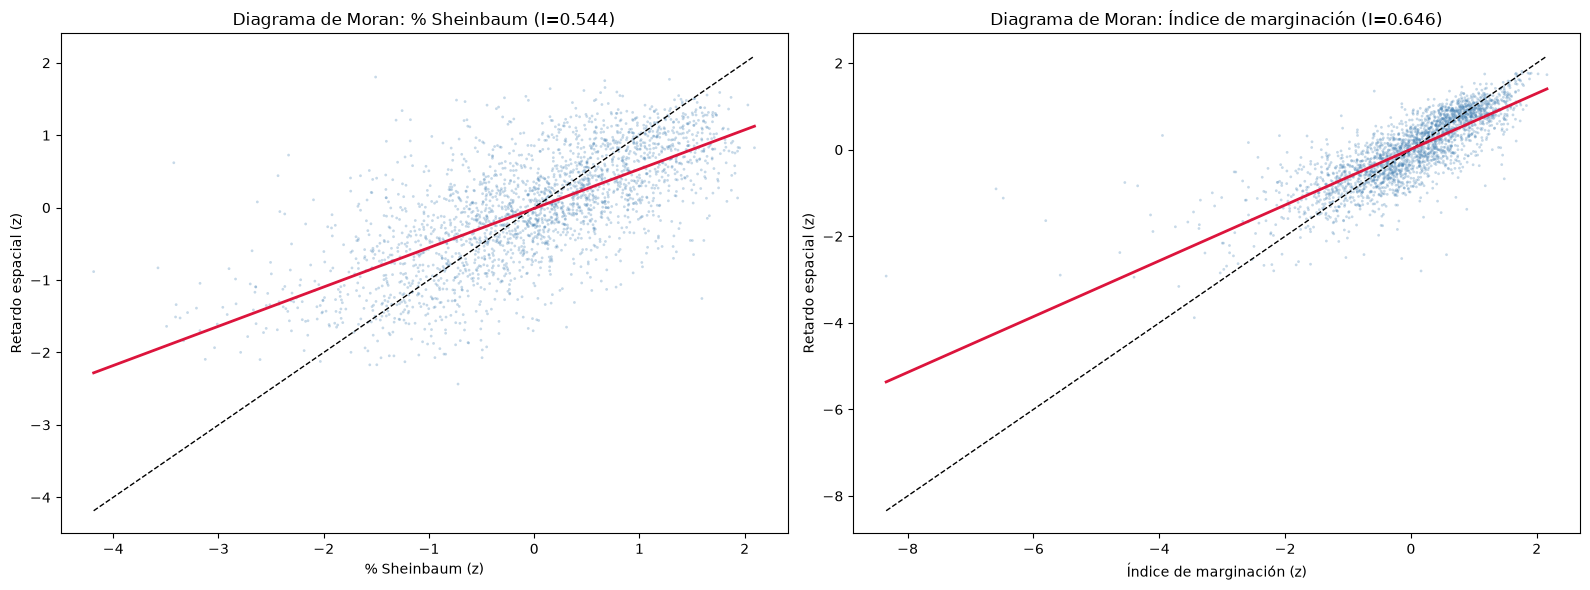

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, col, nombre in zip(axes, ["pct_sheinbaum", "im_2020"],
                          ["% Sheinbaum", "Índice de marginación"]):
    mi = Moran(g[col], w, permutations=999)
    z = (g[col] - g[col].mean()) / g[col].std()
    lag = w.sparse @ z.values
    ax.scatter(z, lag, s=4, alpha=0.3, color="steelblue", edgecolor="none")
    ax.plot([z.min(), z.max()], [z.min(), z.max()], "k--", lw=1)
    ax.plot([z.min(), z.max()], np.polyval(np.polyfit(z, lag, 1),
                                           [z.min(), z.max()]), color="crimson", lw=2)
    ax.set_xlabel(f"{nombre} (z)")
    ax.set_ylabel("Retardo espacial (z)")
    ax.set_title(f"Diagrama de Moran: {nombre} (I={mi.I:.3f})", fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(FIGURAS, "moran_scatter.png"), dpi=150, bbox_inches="tight")
plt.show()

/home/appuser/.local/lib/python3.12/site-packages/esda/moran.py:1398: RuntimeWarning: invalid value encountered in divide
  self.z_sim = (self.Is - self.EI_sim) / self.seI_sim


Distribución de cuadrantes LISA (% Sheinbaum):
cuadrante
Alto-Alto    1008
Bajo-Bajo     871
Alto-Bajo     309
Bajo-Alto     274
Name: count, dtype: int64
Clusters significativos (p<0.05): 856 municipios


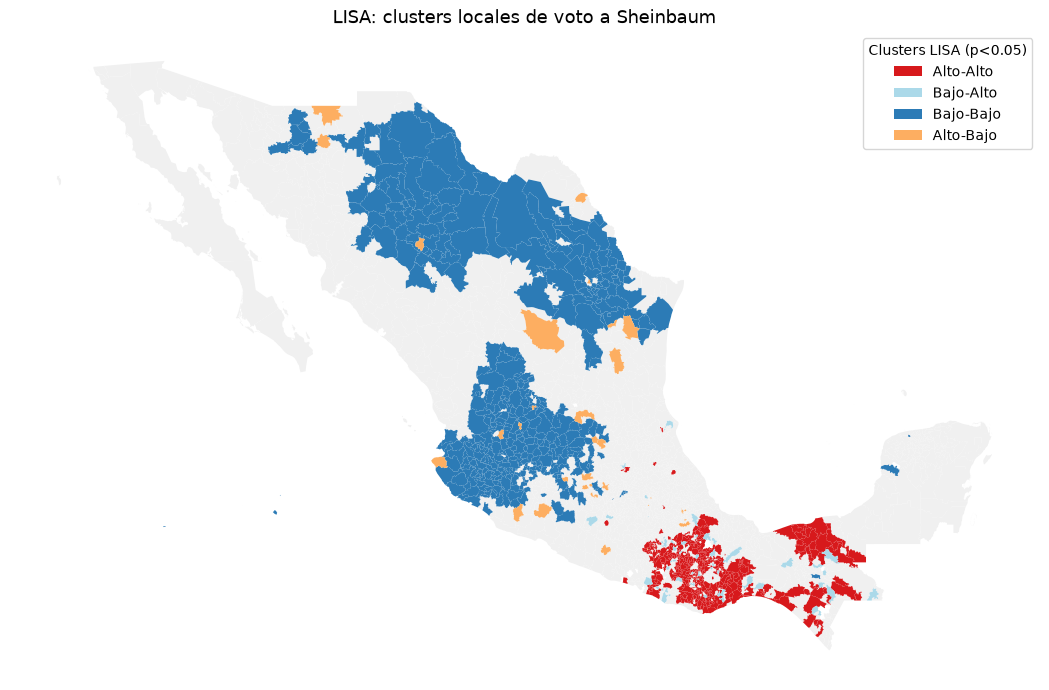

In [4]:
lisa = Moran_Local(g["pct_sheinbaum"], w, permutations=999)
g["cuadrante"] = lisa.q
g["significativo"] = (lisa.p_sim < 0.05)
print("Distribución de cuadrantes LISA (% Sheinbaum):")
print(g["cuadrante"].value_counts().rename({1: "Alto-Alto", 2: "Bajo-Alto",
                                            3: "Bajo-Bajo", 4: "Alto-Bajo"}))
print(f"Clusters significativos (p<0.05): {g['significativo'].sum()} municipios")

fig, ax = plt.subplots(figsize=(11, 7))
etiquetas = {1: "Alto-Alto", 2: "Bajo-Alto", 3: "Bajo-Bajo", 4: "Alto-Bajo"}
colores = {1: "#d7191c", 2: "#abd9e9", 3: "#2c7bb6", 4: "#fdae61"}
g[~g["significativo"]].plot(ax=ax, color="#f0f0f0")
for q in [1, 2, 3, 4]:
    sub = g[g["significativo"] & (g["cuadrante"] == q)]
    if len(sub):
        sub.plot(ax=ax, color=colores[q], label=etiquetas[q], edgecolor="none")
ax.legend(title="Clusters LISA (p<0.05)")
ax.set_title("LISA: clusters locales de voto a Sheinbaum", fontsize=13)
ax.set_axis_off()
plt.tight_layout()
plt.savefig(os.path.join(FIGURAS, "lisa_sheinbaum.png"), dpi=150, bbox_inches="tight")
plt.show()